# MLOps Training 2026/2027 — Task 2

## Notebook 6 — Train, Tune, Evaluate

This notebook trains a simple baseline, tunes a logistic-regression model on validation, and evaluates the selected model on the test set once at the end. Because late delivery is the minority class, recall and precision are reported alongside F1, ROC-AUC, and the confusion matrix.

**Inputs:** transformed matrices and labels from Notebook 5.

**Outputs:** `06_model.joblib`, `06_results.json`, and `06_confusion_matrix.png`.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(r"C:\Users\HP\Desktop\MLOps")
TASK2_ROOT = PROJECT_ROOT / "Task2"
ARTIFACTS_DIR = TASK2_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

import joblib
from scipy import sparse
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay)

X_train = sparse.load_npz(ARTIFACTS_DIR / "features" / "05_X_train.npz")
X_validation = sparse.load_npz(ARTIFACTS_DIR / "features" / "05_X_validation.npz")
X_test = sparse.load_npz(ARTIFACTS_DIR / "features" / "05_X_test.npz")
y_train = np.load(ARTIFACTS_DIR / "features" / "05_y_train.npy")
y_validation = np.load(ARTIFACTS_DIR / "features" / "05_y_validation.npy")
y_test = np.load(ARTIFACTS_DIR / "features" / "05_y_test.npy")


## 1. Baseline

The baseline always predicts the majority class. It establishes a reference point and is not expected to detect late orders well.


In [2]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_validation)
baseline_metrics = {"accuracy": accuracy_score(y_validation, baseline_pred), "precision": precision_score(y_validation, baseline_pred, zero_division=0), "recall": recall_score(y_validation, baseline_pred, zero_division=0), "f1": f1_score(y_validation, baseline_pred, zero_division=0)}
print(baseline_metrics)


{'accuracy': 0.9465791292328957, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


## 2. Tune on validation

The regularization parameter is selected using validation recall, with F1 used as a secondary reference. The test set remains untouched.


In [3]:
candidates = []
for c_value in [0.1, 1.0]:
    model = LogisticRegression(max_iter=300, class_weight="balanced", C=c_value, solver="liblinear", random_state=42)
    model.fit(X_train, y_train)
    pred = model.predict(X_validation)
    proba = model.predict_proba(X_validation)[:, 1]
    candidates.append({"C": c_value, "model": model, "recall": recall_score(y_validation, pred, zero_division=0), "precision": precision_score(y_validation, pred, zero_division=0), "f1": f1_score(y_validation, pred, zero_division=0), "roc_auc": roc_auc_score(y_validation, proba), "pr_auc": average_precision_score(y_validation, proba)})

selected = max(candidates, key=lambda row: (row["recall"], row["f1"]))
print(pd.DataFrame([{k:v for k,v in row.items() if k != "model"} for row in candidates]))
print("Selected C:", selected["C"])


     C    recall  precision        f1   roc_auc    pr_auc
0  0.1  0.948254   0.068237  0.127312  0.733459  0.130611
1  1.0  0.923674   0.069026  0.128452  0.721490  0.128303
Selected C: 0.1


## 3. Final test evaluation

Only now is the selected model evaluated on the held-out test split.


{'accuracy': 0.1368944786123972, 'precision': 0.07091301436118759, 'recall': 0.9958202716823407, 'f1': 0.1323978883023062, 'roc_auc': 0.6664115807609401, 'pr_auc': 0.11612888798022997}
              precision    recall  f1-score   support

     on_time       1.00      0.08      0.14     13514
        late       0.07      1.00      0.13       957

    accuracy                           0.14     14471
   macro avg       0.53      0.54      0.14     14471
weighted avg       0.93      0.14      0.14     14471



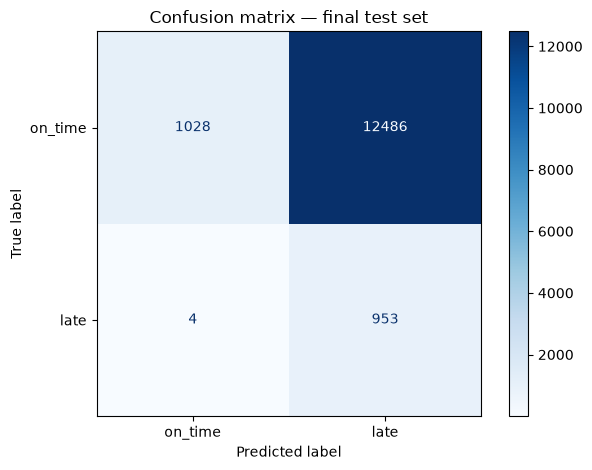

In [4]:
final_model = selected["model"]
test_pred = final_model.predict(X_test)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_metrics = {"accuracy": float(accuracy_score(y_test, test_pred)), "precision": float(precision_score(y_test, test_pred, zero_division=0)), "recall": float(recall_score(y_test, test_pred, zero_division=0)), "f1": float(f1_score(y_test, test_pred, zero_division=0)), "roc_auc": float(roc_auc_score(y_test, test_proba)), "pr_auc": float(average_precision_score(y_test, test_proba))}
print(test_metrics)
print(classification_report(y_test, test_pred, target_names=["on_time", "late"], zero_division=0))
cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["on_time", "late"]).plot(cmap="Blues")
plt.title("Confusion matrix — final test set")
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "charts" / "06_confusion_matrix.png", dpi=160)
plt.show()
plt.close()


## 4. Save model and results


In [5]:
joblib.dump(final_model, ARTIFACTS_DIR / "models" / "06_model.joblib")
results = {"baseline_validation": baseline_metrics, "selected_C": float(selected["C"]), "validation_selection_rule": "maximize recall, then F1", "validation_candidates": [{k: float(v) for k,v in row.items() if k != "model"} for row in candidates], "final_test": test_metrics, "test_was_used_for_selection": False}
(ARTIFACTS_DIR / "reports" / "06_results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print("Saved model, results summary, and confusion matrix.")


Saved model, results summary, and confusion matrix.


In [6]:
assert (ARTIFACTS_DIR / "models" / "06_model.joblib").exists()
assert (ARTIFACTS_DIR / "reports" / "06_results.json").exists()
assert (ARTIFACTS_DIR / "charts" / "06_confusion_matrix.png").exists()
print("ALL NOTEBOOK 6 CHECKS PASSED")


ALL NOTEBOOK 6 CHECKS PASSED
